# Local Lipschitz ratio from the ambient sweep

Same analysis as `lipschitz_ratio_ae_sampled_sweep.ipynb`, but on `scripts.python.generate_ambient_sweep`'s output instead of the autoencoder-sampled sweep: for one sublayer `src -> dst`, each row is one independently-sampled ambient point `src_vec` (a real vocab-cloud anchor plus isotropic `N(0, tau^2 I)` noise -- no trained autoencoder involved) and the real sublayer output `dst_vec` for that point (spliced into real context activations -- see `scripts/python/generate_ambient_sweep.py`'s docstring).

Like the AE-sampled sweep, samples are independent per **position**, so positions are kept **separate** here rather than pooled: one ratio distribution and plot per `(sublayer, position)`.

```
g(x, y) = ||f(x) - f(y)|| / ||x - y||
```
computed via `pdist` over the `n` sampled points at each position (`src_vec`/`dst_vec` share row ordering, so the ratio is elementwise, no re-indexing needed).

In [6]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from scipy.spatial.distance import pdist

from execute.sharded_writer import load_shard_rows
from scripts.python.estimate_colipschitz_gpd import fit_gpd_tail

## Config

In [2]:
# Output dir from scripts.python.generate_ambient_sweep, e.g.
# onnx_models/simple_stories/ambient_sweep (see configs/simple_stories.toml).
# Loaded via execute.sharded_writer.load_shard_rows against the NFS manifest
# -- this resolves shards through ensure_local (pulling from the remote store
# if needed) or reads them directly off scratch if the sweep was run with
# --no-push.
#
# PULL_DIR: this notebook doesn't necessarily run on the GPU node that
# produced the data (load_shard_rows/ensure_local default to node-local
# scratch, $NEW_JAC_SCRATCH, which isn't writable/present on e.g. a login
# node), so pull any missing shards into an NFS-resident cache dir instead --
# a few dozen MB per shard, fine to keep on NFS for notebook use (unlike a
# full sweep's worth of shards, see CLAUDE.md's scratch-vs-NFS guidance).
SWEEP_DIR = "onnx_models/simple_stories/ambient_sweep"
SRC_LAYER = "add_34"
DST_LAYER = "add_36"
SAMPLE_IDX = 0  # must match the --sample-idx the sweep was generated with
N_PAIRS_MAX = 20000  # subsample before pdist if a position has more than this many rows
PULL_DIR = ".nfs_shard_cache"  # None to use node-local scratch instead (e.g. when running via srun on the GPU node)

## Load one sublayer's shard(s)

In [3]:
import json

layer_key = f"{SWEEP_DIR}/{SRC_LAYER}.{DST_LAYER}.sample{SAMPLE_IDX}"
rows = load_shard_rows(".", layer_key, dataset_names=["src_vec", "dst_vec", "pos"], pull_dir=PULL_DIR)
with open(layer_key + ".manifest.json") as f:
    attrs = json.load(f)["attrs"]
print("attrs:", attrs)
print("total rows:", rows["src_vec"].shape[0])
seq = int(attrs["seq"])

attrs: {'sample_idx': 0, 'n_samples': 1000, 'seq': 8, 'd_model': 384, 'tau': 1.0}
total rows: 8000


## Per-position Lipschitz ratio

In [4]:
def ratio_for_position(rows: dict[str, np.ndarray], pos: int, n_pairs_max: int, seed: int = 0):
    mask = rows["pos"] == pos
    src = rows["src_vec"][mask]
    dst = rows["dst_vec"][mask]
    n = src.shape[0]
    if n > n_pairs_max:
        idx = np.random.default_rng(seed).choice(n, n_pairs_max, replace=False)
        src, dst = src[idx], dst[idx]
    input_dist = pdist(src)
    output_dist = pdist(dst)
    # ambient_sample draws anchors WITH replacement (np.random.Generator.integers),
    # so exact-duplicate anchors (and, rarely, near-duplicate noisy points) across
    # rows are expected -- pairs with input_dist == 0 make the ratio 0/0 = nan, so
    # drop them rather than letting them poison min/median/max and the GPD fit.
    nonzero = input_dist > 0
    n_dropped = (~nonzero).sum()
    if n_dropped:
        print(f"  pos={pos}: dropping {n_dropped} zero-input-distance pair(s) (duplicate sampled points)")
    return input_dist[nonzero], output_dist[nonzero]


per_pos_results = {}
for pos in range(seq):
    input_dist, output_dist = ratio_for_position(rows, pos, N_PAIRS_MAX)
    g = output_dist / input_dist
    result = fit_gpd_tail(g, threshold=None, threshold_quantile=None, n_tail_min=200)
    per_pos_results[pos] = dict(input_dist=input_dist, output_dist=output_dist, g=g, result=result)
    print(f"pos={pos}: N={g.size} pairs, g min/median/max = {g.min():.4g}/{np.median(g):.4g}/{g.max():.4g}, "
          f"c_hat={result['c_hat']}")

pos=0: N=499500 pairs, g min/median/max = 0.9645/0.9986/1.029, c_hat=0.953697224198341
pos=1: N=499500 pairs, g min/median/max = 0.9609/0.9987/1.033, c_hat=0.9248148529815318
pos=2: N=499500 pairs, g min/median/max = 0.9556/0.9986/1.029, c_hat=0.9297512993717721
pos=3: N=499500 pairs, g min/median/max = 0.9636/0.9988/1.028, c_hat=0.9498973365833672
pos=4: N=499500 pairs, g min/median/max = 0.9635/0.9983/1.03, c_hat=0.9598530267611561
pos=5: N=499500 pairs, g min/median/max = 0.9654/0.9987/1.029, c_hat=0.9512375492925088
pos=6: N=499500 pairs, g min/median/max = 0.9671/0.9988/1.031, c_hat=0.9647652305147779
pos=7: N=499500 pairs, g min/median/max = 0.9669/0.9985/1.031, c_hat=0.9548113264938332


## Plots: output vs input distance, per position

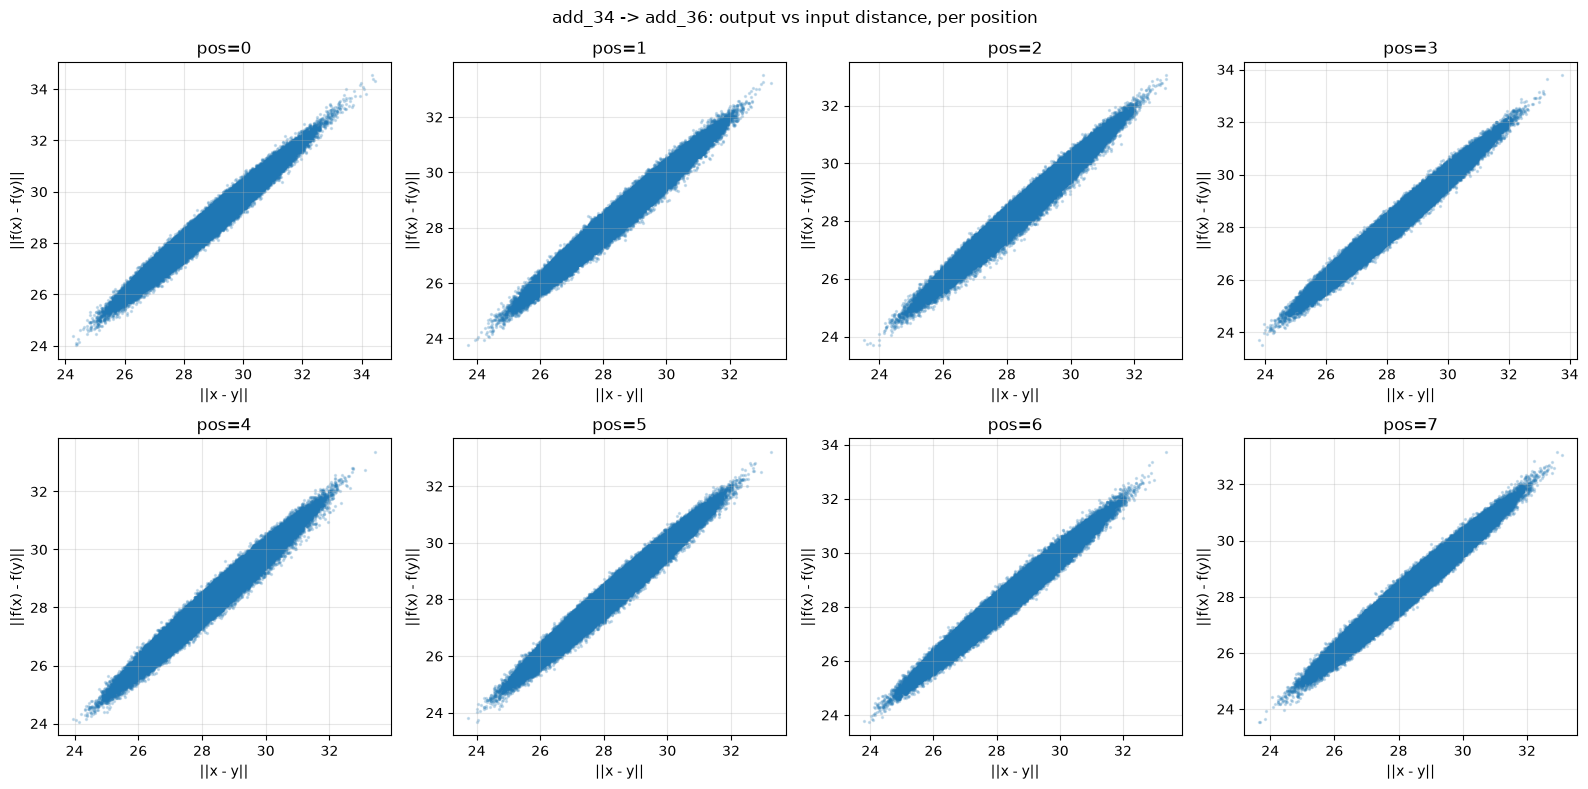

In [8]:
fig, axes = plt.subplots(2, (seq + 1) // 2, figsize=(4 * ((seq + 1) // 2), 8), squeeze=False)
axes = axes.flatten()
for pos in range(seq):
    r = per_pos_results[pos]
    ax = axes[pos]
    ax.scatter(r["input_dist"], r["output_dist"], s=2, alpha=0.2)
    ax.set_xlabel("||x - y||")
    ax.set_ylabel("||f(x) - f(y)||")
    ax.set_title(f"pos={pos}")
    ax.grid(True, alpha=0.3)
for ax in axes[seq:]:
    ax.axis("off")
fig.suptitle(f"{SRC_LAYER} -> {DST_LAYER}: output vs input distance, per position")
fig.tight_layout()
plt.show()

## Plots: Lipschitz ratio distribution + GPD tail, per position

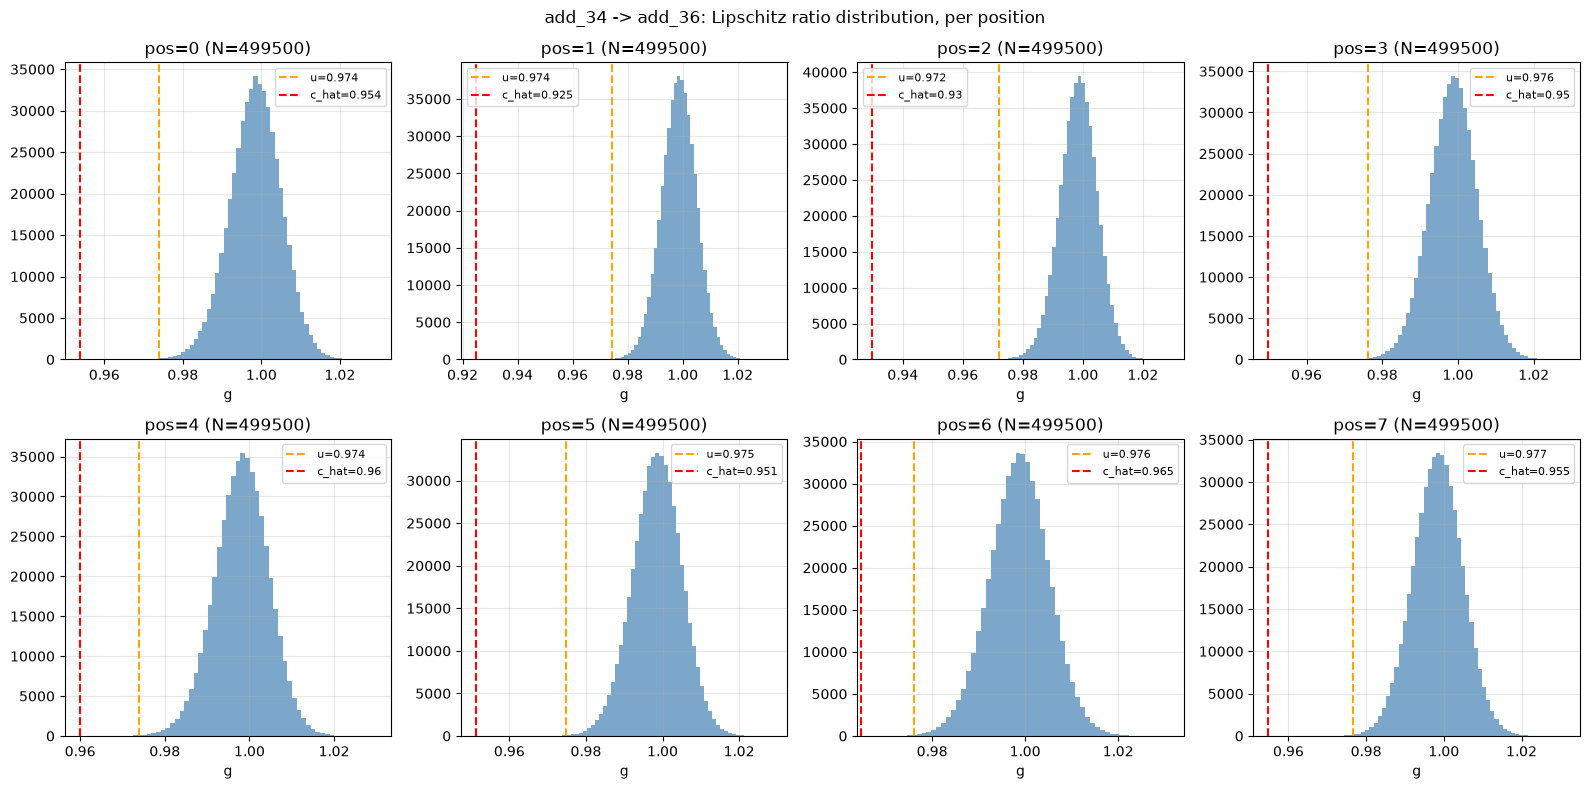

In [9]:
from scipy.stats import genpareto

fig, axes = plt.subplots(2, (seq + 1) // 2, figsize=(4 * ((seq + 1) // 2), 8), squeeze=False)
axes = axes.flatten()
for pos in range(seq):
    r = per_pos_results[pos]
    g, result = r["g"], r["result"]
    threshold = result["threshold"]
    ax = axes[pos]
    ax.hist(g, bins=60, color="steelblue", alpha=0.7)
    ax.axvline(threshold, color="orange", linestyle="--", label=f"u={threshold:.3g}")
    if result["c_hat"] is not None:
        ax.axvline(result["c_hat"], color="red", linestyle="--", label=f"c_hat={result['c_hat']:.3g}")
    ax.set_xlabel("g")
    ax.set_title(f"pos={pos} (N={g.size})")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
for ax in axes[seq:]:
    ax.axis("off")
fig.suptitle(f"{SRC_LAYER} -> {DST_LAYER}: Lipschitz ratio distribution, per position")
fig.tight_layout()
plt.show()

## Summary table: c_hat per position

In [7]:
print(f"{'pos':>4}  {'N':>8}  {'g_min':>10}  {'threshold':>10}  {'c_hat':>10}  {'se_c_hat':>10}")
for pos in range(seq):
    result = per_pos_results[pos]["result"]
    c_hat = result["c_hat"]
    se = result.get("se_c_hat")
    print(
        f"{pos:>4}  {result['n_samples']:>8}  {result['g_min_observed']:>10.4g}  "
        f"{result['threshold']:>10.4g}  {c_hat if c_hat is not None else float('nan'):>10.4g}  "
        f"{se if se is not None else float('nan'):>10.4g}"
    )

 pos         N       g_min   threshold       c_hat    se_c_hat
   0    499500      0.9645       0.974      0.9537     0.01111
   1    499500      0.9609      0.9744      0.9248     0.05965
   2    499500      0.9556      0.9722      0.9298     0.03161
   3    499500      0.9636      0.9763      0.9499     0.01571
   4    499500      0.9635      0.9739      0.9599    0.003125
   5    499500      0.9654      0.9748      0.9512     0.01556
   6    499500      0.9671      0.9761      0.9648    0.001943
   7    499500      0.9669      0.9766      0.9548     0.01372
